In [3]:
import numpy as np
from pathlib import Path
import timeit
import pandas as pd
import sys
sys.path.insert(1, '../')
import util
from util.dynamics import temp_response, environmental_update
from util.plot import lighten_color

import scipy as sp
import matplotlib.pyplot as plt
# import tqdm
from matplotlib.lines import Line2D

import tqdm
import seaborn as sns
from scipy.optimize import fsolve
# import netCDF4 as nc
import os

# extended ssps

In [25]:
df = pd.read_excel('../../Data/extendedSSPs.xlsx')
dfs = {s: df[df['scenario']==s].set_index('quantile').iloc[:,9:].transpose() for s in ['ssp119','ssp126','ssp534-over']}

In [11]:
dfs['ssp126'].head()

quantile,mean,median,0.05,0.95
1850-07-01 00:00:00,-0.036296,-0.042477,-0.158622,0.101991
1851-07-01 00:00:00,-0.006617,-0.011424,-0.125681,0.126811
1852-07-01 00:00:00,-0.003862,-0.008641,-0.123915,0.130445
1853-07-01 00:00:00,-0.006655,-0.011269,-0.125396,0.126352
1854-07-01 00:00:00,-0.023638,-0.030521,-0.141879,0.111638


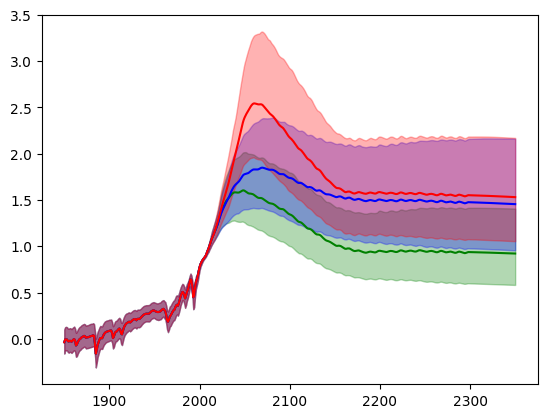

In [75]:
colors = ['green','blue','red']
for i,s in enumerate(['ssp119','ssp126','ssp534-over']):
    plt.fill_between(np.arange(1850,2351), dfs[s][0.05], dfs[s][0.95], color=colors[i],alpha=0.3)
    plt.plot(np.arange(1850,2351), dfs[s]['mean'],color=colors[i])

In [69]:
overshoots = {}
for s in ['ssp119', 'ssp126', 'ssp534-over']:
    overshoots[s] = dict(T_conv = [dfs[s][0.05][-100:].mean(), dfs[s][0.95][-100:].mean()], 
                         T_peak = [dfs[s][0.05].max(), dfs[s][0.95].max()] )
    # arr = []
    # for i,m in enumerate([0.05,0.95]):
    #     locs = np.where(np.abs())

In [70]:
overshoots['ssp534-over']

{'T_conv': [np.float64(1.0746304249805325), np.float64(2.181046920156417)],
 'T_peak': [np.float64(1.9611345023153), np.float64(3.32016735138828)]}

In [56]:
arr = dfs['ssp119'][0.05].to_numpy()
np.argmin(np.abs(arr-overshoots['ssp126']['T_conv'][0]))

np.int64(256)

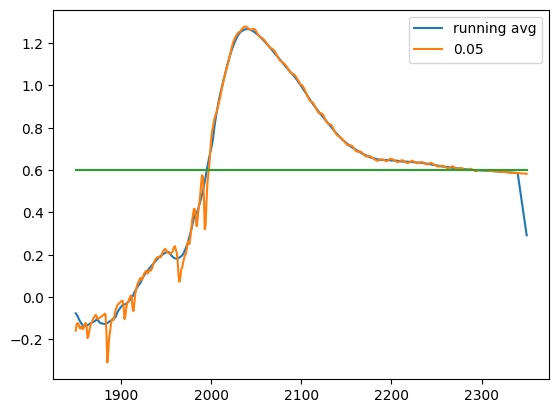

In [101]:
s='ssp119'
m=0.05
N=20
plt.plot(np.arange(1850,2351),np.convolve(dfs[s][m].to_numpy(), 
                                          np.ones(N)/N)[int(np.floor(N/2)):-int(np.floor(N/2))+1],
         label='running avg')
plt.plot(np.arange(1850,2351), dfs[s][m].to_numpy(),label=m)
plt.plot([1850,2350], [overshoots[s]['T_conv'][0]]*2)
plt.legend()

In [95]:
round(N/2)

2

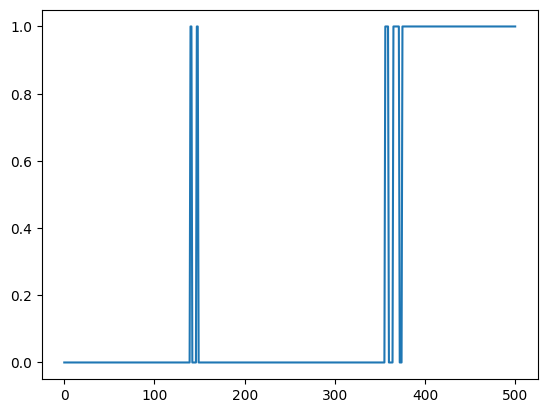

In [68]:
s = 'ssp119'
m = [0.05, 0]
plt.plot((np.abs((dfs[s][m[0]].to_numpy()-overshoots[s]['T_conv'][m[1]]))<=0.05))

In [41]:
np.where(np.abs(arr-overshoots['ssp126']['T_conv'][0])<=0.1)[0]

array([156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 321, 322,
       323, 328, 329, 330, 331, 332, 333, 334, 335, 336, 337, 338, 339,
       340, 341, 342, 343, 344, 345, 346, 347, 348, 349, 350, 351, 352,
       353, 354, 355, 356, 357, 358, 359, 360, 361, 362, 363, 364, 365,
       366, 367, 368, 369, 370, 371, 372, 373, 374, 375, 376, 377, 378,
       379, 380, 381, 382, 383, 384, 385, 386, 387, 388, 389, 390, 391,
       392, 393, 394, 395, 396, 397, 398, 399, 400, 401, 402, 403, 404,
       405, 406, 407, 408, 409, 410, 411, 412, 413, 414, 415, 416, 417,
       418, 419, 420, 421, 422, 423, 424, 425, 426, 427, 428, 429, 430,
       431, 432, 433, 434, 435, 436, 437, 438, 439, 440, 441, 442, 443,
       444, 445, 446, 447, 448, 449, 450, 451, 452, 453, 454, 455, 456,
       457, 458, 459, 460, 461, 462, 463, 464, 465, 466, 467, 468, 469,
       470, 471, 472, 473, 474, 475, 476, 477, 478, 479, 480, 481, 482,
       483, 484, 485, 486, 487, 488, 489, 490, 491, 492, 493, 49

# Schwaab 2024
## Reading .nc files for the 10 scenarios

In [2]:
import xarray as xr

In [9]:
folder = '../../Data/Schwaab 2024/fair_100_mesmer_10_quantiles_tar/'
scenarios = os.listdir(folder)
scenarios = [s[:-3] for s in scenarios]
ds_scens = {s: xr.open_dataset(folder+s+'.nc') for s in scenarios}

In [10]:
print(scenarios)

['Ref_1p5', 'Ren', 'ModAct', 'SP', 'CurPol', 'LD', 'GS', 'ssp534-over', 'ssp119', 'Neg']


In [20]:
np.nanmean(arr['tas'].values)

np.float64(1.2862000237828102)

In [ ]:
(~np.isnan(ds_scens['Ref_1p5']['tas'].to_numpy())).sum()/ds_scens['Ref_1p5']['tas'].size

arr.coords

In [11]:
arrs = {s: np.nanmean(ds_scens[s]['tas'], axis = (2,3)) for s in scenarios}

In [13]:
type(arrs['ssp119'])

numpy.ndarray

In [31]:
ds_scens['ssp119'].coords['quantile'].values

array([0.05, 0.1 , 0.15, 0.2 , 0.25, 0.3 , 0.35, 0.4 , 0.45, 0.5 , 0.55,
       0.6 , 0.65, 0.66, 0.7 , 0.75, 0.8 , 0.85, 0.9 , 0.95, 0.98])

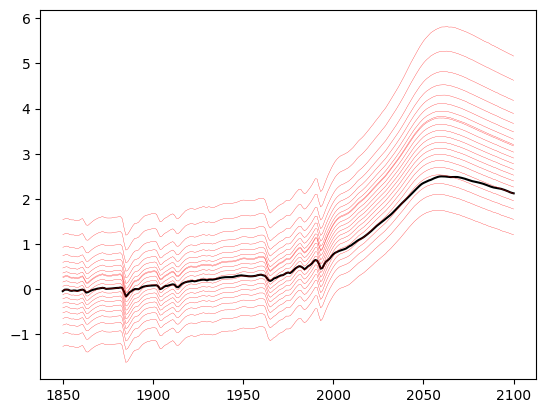

In [33]:
s='ssp534-over'
# plt.plot(np.arange(1850,2101), arrs[s][9,:] )
plt.plot(np.arange(1850,2101), dfs[s]['median'][:len(np.arange(1850,2101))],color='k')
for i,q in enumerate(ds_scens[s].coords['quantile'].values):
    plt.plot(np.arange(1850,2101),arrs[s][i],label=q,color='red',lw=0.2)
# plt.plot(np.arange(1850,2101), arrs['ssp119'][9,:])
# plt.plot(np.arange(1850,2101), arrs[s][0,:] )
# plt.plot(np.arange(1850,2101), arrs[s][-2,:] )

In [34]:
ref = xr.open_dataset('../../Data/Schwaab 2024/reference_data_1850_1900/dta_ref_1850_1900.nc')

In [36]:
print(ref.coords['ESM'])

<xarray.DataArray 'ESM' (ESM: 25)> Size: 2kB
array(['ACCESS-CM2', 'ACCESS-ESM1-5', 'AWI-CM-1-1-MR', 'CESM2', 'CESM2-WACCM',
       'CMCC-CM2-SR5', 'CNRM-CM6-1', 'CNRM-CM6-1-HR', 'CNRM-ESM2-1', 'CanESM5',
       'E3SM-1-1', 'FGOALS-f3-L', 'FGOALS-g3', 'FIO-ESM-2-0',
       'HadGEM3-GC31-LL', 'HadGEM3-GC31-MM', 'IPSL-CM6A-LR', 'MCM-UA-1-0',
       'MPI-ESM1-2-HR', 'MPI-ESM1-2-LR', 'MRI-ESM2-0', 'NESM3', 'NorESM2-LM',
       'NorESM2-MM', 'UKESM1-0-LL'], dtype='<U15')
Coordinates:
  * ESM      (ESM) <U15 2kB 'ACCESS-CM2' 'ACCESS-ESM1-5' ... 'UKESM1-0-LL'


# Using PROVIDE Project scenarios
Robin Lamboll, Joeri Rogelj, & Carl-Friedrich Schleussner. (2025). Scenario emissions and temperature data for PROVIDE project (v1.3.0) [Data set]. Zenodo. https://doi.org/10.5281/zenodo.11108741

https://pure.iiasa.ac.at/id/eprint/18130/1/essoar.10511875.2.pdf for description

In [4]:
folder = '../../Data/PROVIDE 2025/'
cols = list(pd.read_csv(folder+'post-2100_inc_redundanttier1_temperature_summary.csv',nrows=1))
df = pd.read_csv(folder+'post-2100_inc_redundanttier1_temperature_summary.csv',
                 usecols = [c for c in cols if (c != 'quantile') and (c!= 'atomic_scen')]).set_index('scenario').T
df.index.names=['year']
# df=df.rename(columns={'scenario':''})
scenarios = df.columns.values

In [66]:
df.head()

scenario,CurPol_SAP,CurPol_OS_1.5C,ModAct_OS_1.5C,ModAct_OS_1C,ModAct_SAP,ssp534-over,Neg_SAP,GS_NZGHG,Ren_NZCO2,Neg_NZGHG,Ref_1p5,Neg_OS_0C,LD_NZGHG,SP_NZGHG,ssp119
year,,,,,,,,,,,,,,,
quantile,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5
1850,0.01,0.01,0.01,0.01,0.01,0.01,0.01,0.01,0.01,0.01,0.01,0.01,0.01,0.01,0.01
1851,0.0202,0.0202,0.0202,0.0202,0.0202,0.0202,0.0202,0.0202,0.0202,0.0202,0.0202,0.0202,0.0202,0.0202,0.0202
1852,0.0275,0.0275,0.0275,0.0275,0.0275,0.0275,0.0275,0.0275,0.0275,0.0275,0.0275,0.0275,0.0275,0.0275,0.0275
1853,0.0225,0.0225,0.0225,0.0225,0.0225,0.0225,0.0225,0.0225,0.0225,0.0225,0.0225,0.0225,0.0225,0.0225,0.0225


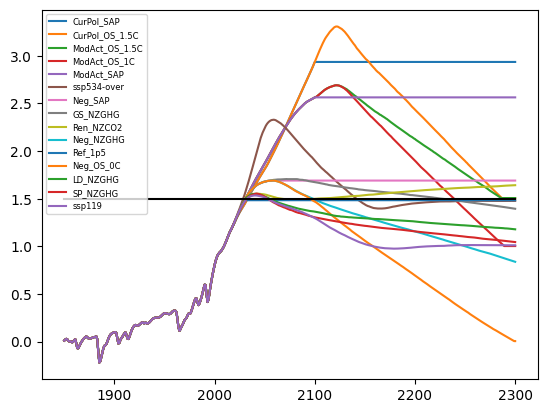

In [126]:
for s in scenarios:
    # if 'OS' in s or 'over' in s:
    plt.plot(np.arange(1850,2301), df[s],label=s)
plt.legend(fontsize=6)
# plt.plot([1850,2300],[1.5]*2,color='k')

(1.5, 2.0)

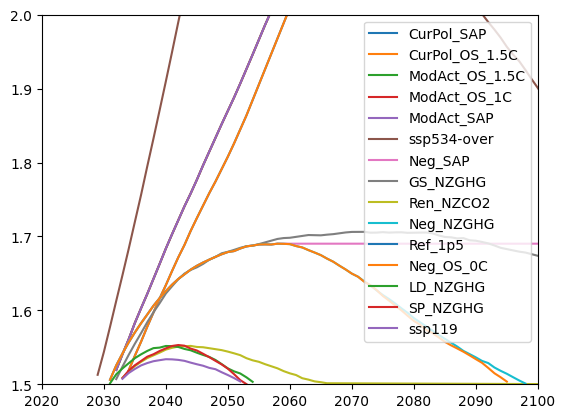

In [133]:
for s in scenarios:
    # if 'OS' in s or 'over' in s:
    plt.plot(np.arange(1850,2301)[df[s]>1.5], df[s][df[s]>1.5],label=s)
plt.legend()
plt.xlim([2020,2100])
plt.ylim([1.5,2])

<Axes: xlabel='year'>

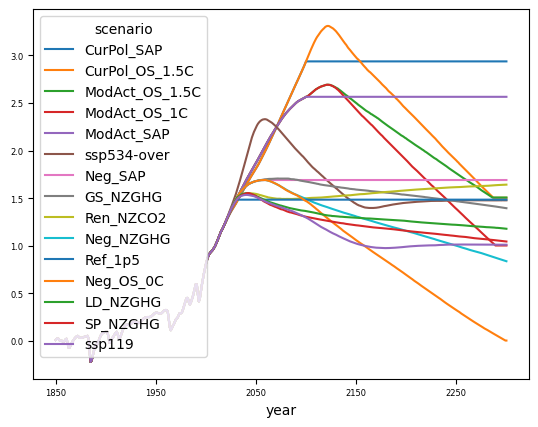

In [106]:
df.plot(fontsize=6)

(-0.02, 0.0)

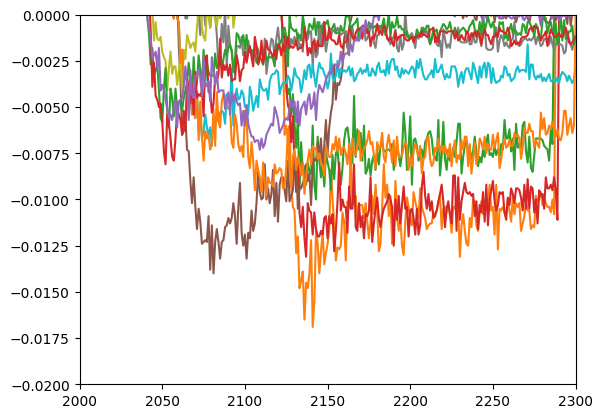

In [109]:
for s in scenarios:
    plt.plot(np.arange(1851,2301), np.diff(df[s]),label=s)
# plt.legend(fontsize=6)
plt.xlim([2000,2300])
plt.ylim([-0.02,0.0])

In [ ]:
plt.scatter(np.arange(15),np.arg)

In [87]:
np.where(np.abs(np.diff(df[s]))<=1e-5)[0]+1850

array([1950, 2179, 2223, 2225, 2251, 2262, 2264, 2272, 2273, 2283, 2284,
       2286, 2292, 2294, 2295, 2299])

In [83]:
df[s][150:]

year
2000    0.8017
2001    0.8437
2002    0.8779
2003    0.9044
2004    0.9211
         ...  
2296    1.0107
2297    1.0106
2298    1.0107
2299    1.0108
2300    1.0108
Name: ssp119, Length: 301, dtype: float64

In [94]:
np.arange(1850,2301)[150]

np.int64(2000)

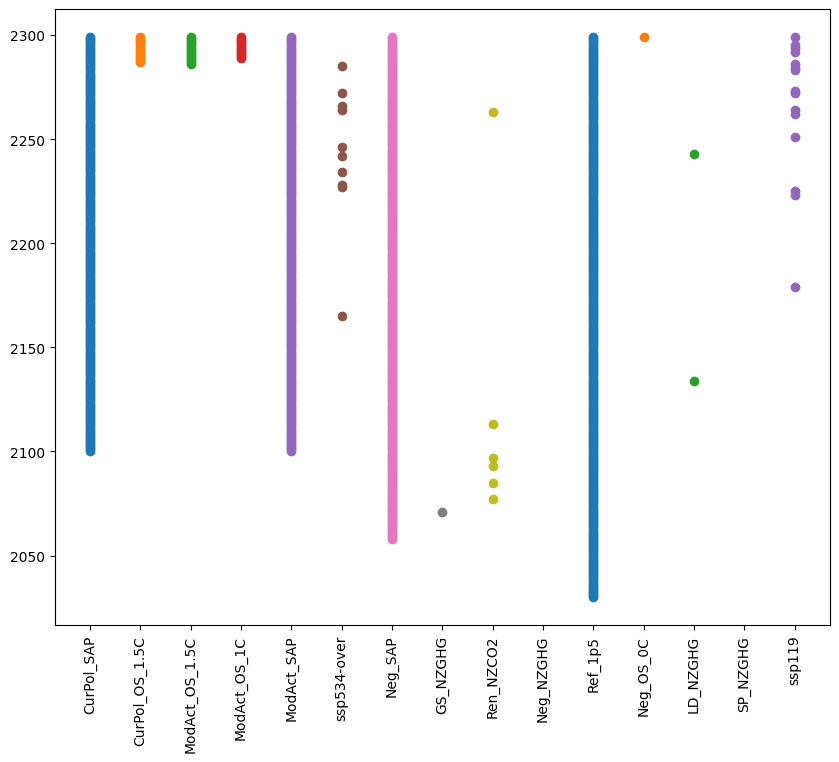

In [112]:
fig,ax = plt.subplots(figsize=(10,8))
for i,s in enumerate(scenarios):
    yr_offset=150
    stat_yrs = np.where(np.abs(np.diff(df[s][yr_offset:]))<=1e-5)[0]+1850 + yr_offset
    plt.scatter([i]*len(stat_yrs), stat_yrs)

ax.set_xticks(np.arange(15),labels=scenarios)
ax.xaxis.set_tick_params(labelrotation=90)

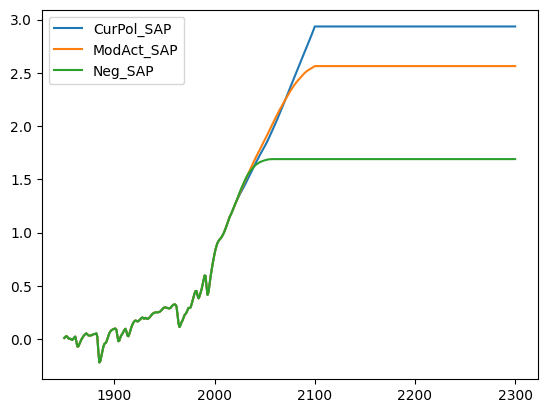

In [118]:
for s in ['CurPol_SAP','ModAct_SAP','Neg_SAP']:
    plt.plot(np.arange(1850,2301), df[s],label=s)
plt.legend()

In [120]:
for s in ['CurPol_SAP','ModAct_SAP','Neg_SAP']:
    print(s, np.mean(df[s][-100:]))

CurPol_SAP 2.9359
ModAct_SAP 2.5639
Neg_SAP 1.6902000000000006


### (Possible) Categorisations
IPCC AR6 WG3: C1 to C8; https://interactive.carbonbrief.org/one-point-five-pathways/index.html

Schleussner 2024 (see (Extended Data) Table 1): PD, PD-OS...etc.; https://www.nature.com/articles/s41586-024-08020-9#Sec1
By eye: CurPol_SAP, ModAct_SAP and Neg_SAP all plateau from below at resp. (2.94C, 2.56C, 1.69C)

In [124]:
def moving_avg(temps,N=20):
    moving_avg = np.cumsum(temps)
    moving_avg[N:] -= moving_avg[:-N]
    moving_avg[N:] /= N
    moving_avg[:N] /= np.arange(1,N+1)
    return moving_avg

def PA_compliant(temps):
    if np.max(temps) > 2:
        return False
    elif np.mean(temps[-20:]) <= 1.5:
        return True
    else:
        return False

def OS_ref(temps,ref=1.5,window=10):
    stat_yrs = np.where(np.abs(df[s].to_numpy()-ref)<=0.05)[0]
    if len(stat_yrs) < 2:
        return False
    elif np.diff(stat_yrs).max()>window:
        return True
    else:
        return False 
    return 

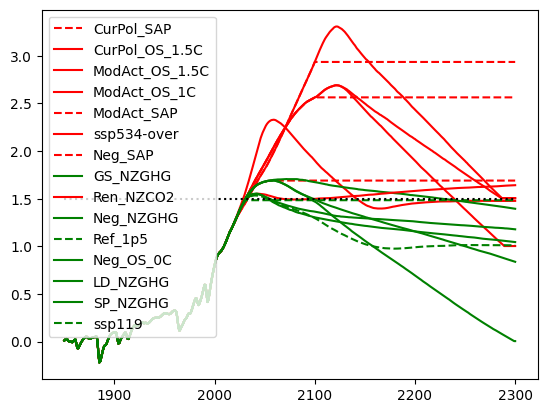

In [5]:
for s in scenarios:
    if PA_compliant(temps = moving_avg(df[s].to_numpy())):
        col = 'green'
    else:
        col = 'red'
    if OS_ref(df[s].to_numpy()):
        ls='-'
    else: 
        ls = '--'
    plt.plot(np.arange(1850,2301), df[s], color=col,label=s,ls=ls)
plt.plot([1850,2300],[1.5]*2,color='k',ls=':')
plt.legend()

In [179]:
df[s].to_numpy()[:2]

array([0.01  , 0.0202])

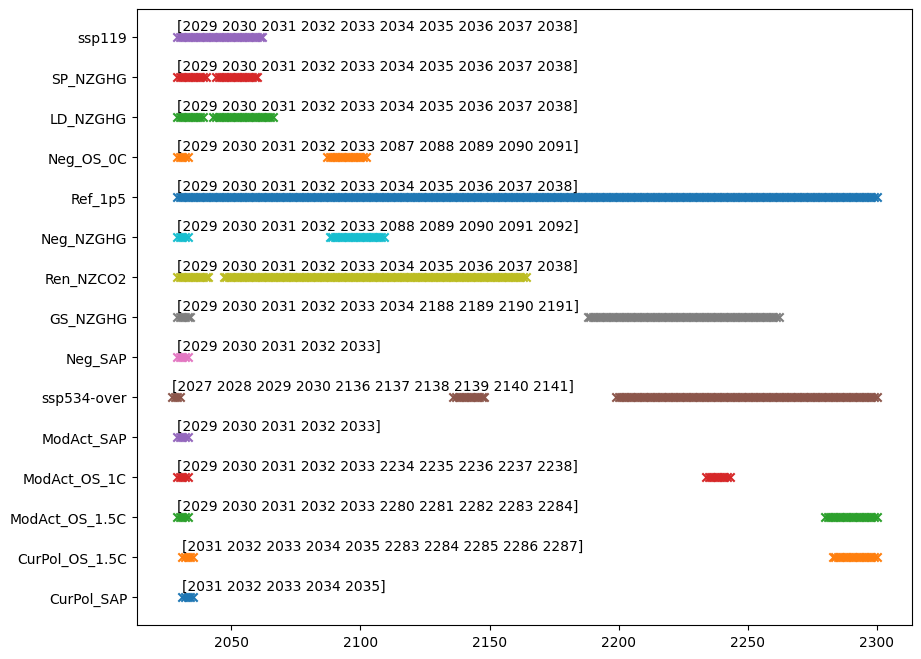

In [225]:
fig,ax = plt.subplots(figsize=(10,8))
for i,s in enumerate(scenarios):
    yr_offset=0
    # stat_yrs = np.where(np.abs(moving_avg(df[s][yr_offset:].to_numpy())-1.5)<=0.05)[0]+1850 + yr_offset
    stat_yrs = np.where(np.abs(df[s][yr_offset:].to_numpy()-1.5)<=0.05)[0]+1850 + yr_offset
    # stat_yrs = np.argmin
    plt.scatter(stat_yrs,[i]*len(stat_yrs),marker='x')
    plt.annotate(stat_yrs[:min(10,len(stat_yrs))], (stat_yrs[0],i+0.1), va='bottom', ha='left')

ax.set_yticks(np.arange(15),labels=scenarios)
ax.yaxis.set_tick_params(labelrotation=0)

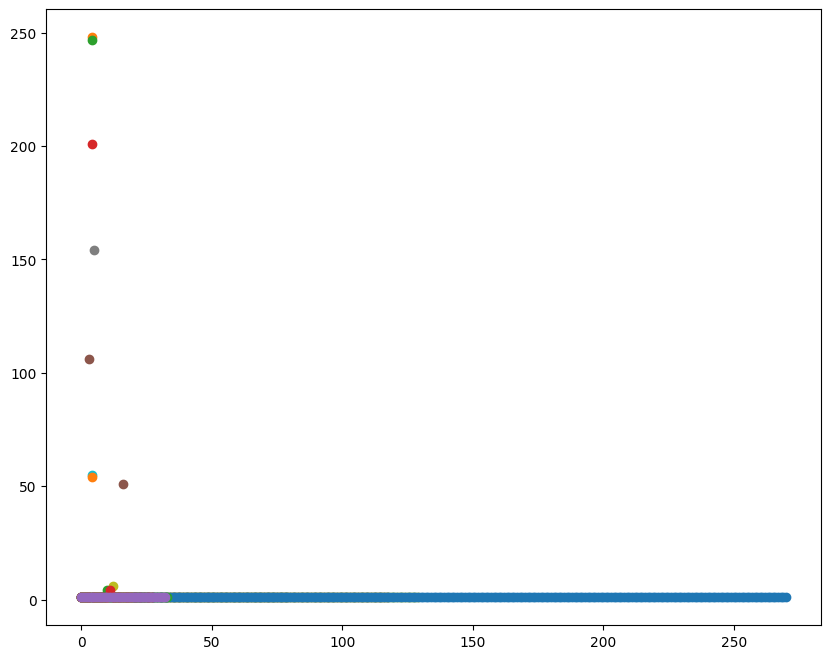

In [230]:
fig,ax = plt.subplots(figsize=(10,8))
for i,s in enumerate(scenarios):
    yr_offset=0
    # stat_yrs = np.where(np.abs(moving_avg(df[s][yr_offset:].to_numpy())-1.5)<=0.05)[0]+1850 + yr_offset
    stat_yrs = np.where(np.abs(df[s][yr_offset:].to_numpy()-1.5)<=0.05)[0]+1850 + yr_offset
    # stat_yrs = np.argmin
    plt.scatter(np.arange(len(stat_yrs)-1), np.diff(stat_yrs))
    # plt.annotate(stat_yrs[:min(10,len(stat_yrs))], (stat_yrs[0],i+0.1), va='bottom', ha='left')

# ax.set_yticks(np.arange(15),labels=scenarios)
# ax.yaxis.set_tick_params(labelrotation=0)

In [219]:
np.argmin(np.abs(df[s].to_numpy() - 1.5))

np.int64(203)

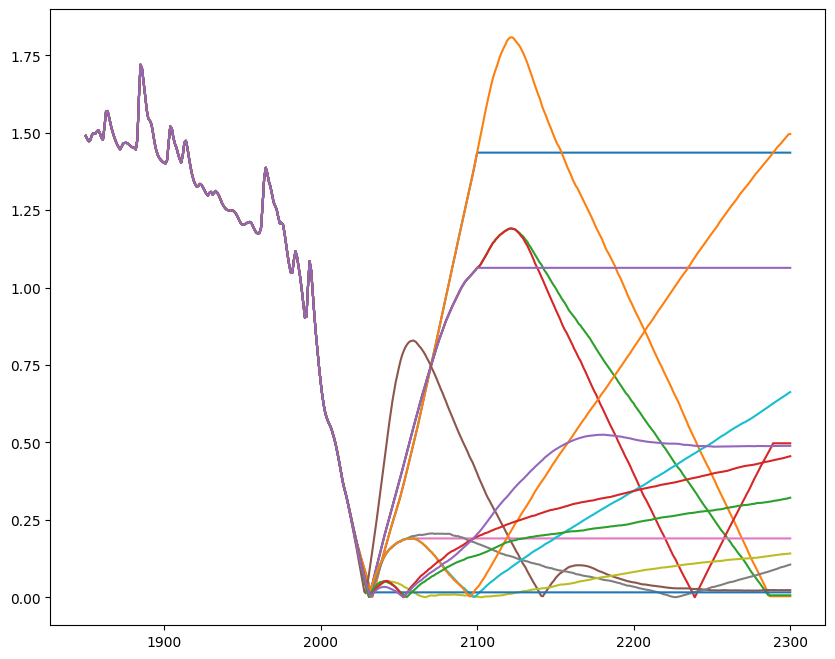

In [213]:
fig,ax = plt.subplots(figsize=(10,8))
for i,s in enumerate(scenarios):
    # yr_offset=0
    # stat_yrs = np.where(np.diff(np.abs(moving_avg(df[s][yr_offset:].to_numpy())-1.5))<=1e-10)[0]+1850 + yr_offset
    plt.plot(np.arange(1850,2301), np.abs(df[s]-1.5))
    # plt.scatter(stat_yrs,[i]*len(stat_yrs),marker='x')

# ax.set_yticks(np.arange(15),labels=scenarios)
# ax.yaxis.set_tick_params(labelrotation=0)

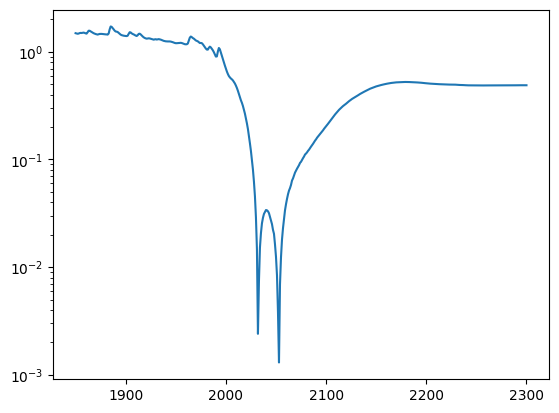

In [232]:
plt.plot(np.arange(1850,2301), np.abs(df['ssp119']-1.5))
plt.yscale('log')
# plt.ylim(1e-3,1e-1)

In [201]:
df['CurPol_SAP'].loc['2000':'2050']

year
2000    0.8017
2001    0.8437
2002    0.8779
2003    0.9044
2004    0.9211
2005    0.9345
2006    0.9449
2007    0.9571
2008    0.9743
2009    0.9919
2010    1.0141
2011    1.0386
2012    1.0655
2013    1.0944
2014    1.1221
2015    1.1452
2016    1.1640
2017    1.1848
2018    1.2082
2019    1.2311
2020    1.2559
2021    1.2779
2022    1.2979
2023    1.3199
2024    1.3387
2025    1.3562
2026    1.3745
2027    1.3911
2028    1.4077
2029    1.4247
2030    1.4428
2031    1.4619
2032    1.4803
2033    1.4991
2034    1.5187
2035    1.5385
2036    1.5575
2037    1.5778
2038    1.5970
2039    1.6162
2040    1.6341
2041    1.6532
2042    1.6716
2043    1.6884
2044    1.7074
2045    1.7248
2046    1.7418
2047    1.7585
2048    1.7742
2049    1.7911
2050    1.8079
Name: CurPol_SAP, dtype: float64

(1.4, 1.6)

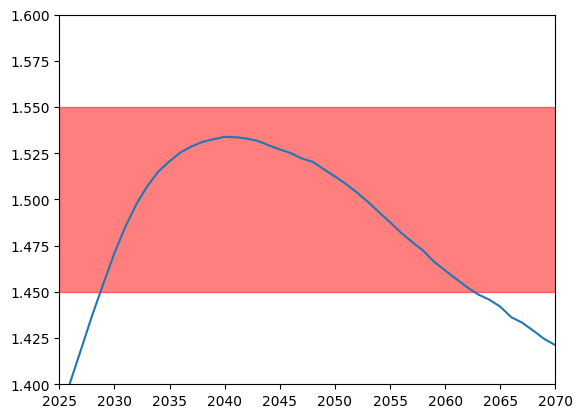

In [245]:
plt.plot(np.arange(1850,2301), df['ssp119'])
plt.fill_between([2025,2070], [1.45]*2, [1.55]*2,color='r',alpha=0.5)
plt.xlim([2025,2070])
plt.ylim(1.4,1.6)

In [153]:
print(len(np.arange(1850,2301)))
print(len(np.convolve(df[s].to_numpy(),np.ones(N)/N,mode='valid')))

451
432


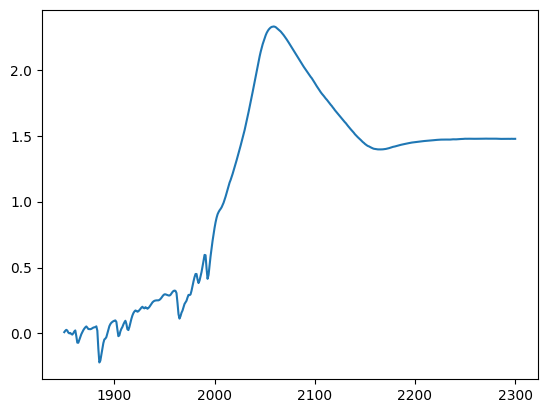

In [142]:
plt.plot(np.arange(1850,2301),df['ssp534-over'])

In [148]:
print(df['ssp534-over'].to_numpy()[-20:])

[1.4779 1.4775 1.4771 1.4766 1.4764 1.4764 1.4765 1.4762 1.4761 1.4764
 1.4767 1.4769 1.477  1.4769 1.4764 1.4772 1.4766 1.4767 1.4768 1.4769]


## visualising pathways more coherently

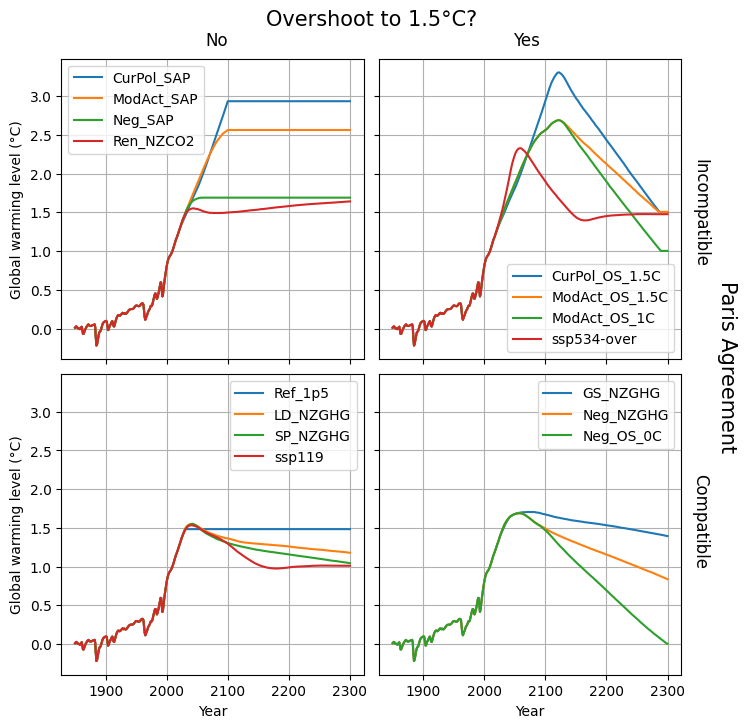

In [157]:
fig,axs=plt.subplots(nrows=2,ncols=2,figsize=(8,8),sharex=True,sharey=True)
plt.subplots_adjust(wspace=0.05,hspace=0.05)
# axs[0,0].set_xlim(2000,2300)
# axs[0,0].set_ylim(0,3.5)
# axs[0,0].set_ylim(-0.01,0.01)
n=0 # nth derivative
N=1 # window for moving_avg
for s in scenarios:
    temp=df[s].to_numpy()
    # axs[int(PA_compliant(moving_avg(temp))), int(OS_ref(temp,ref=1.5))].plot(np.arange(1850,2301), temp, label=s)
    axs[int(PA_compliant(moving_avg(temp))), int(OS_ref(temp,ref=1.5))].plot(np.arange(1850+n,2301), 
                                                                             moving_avg(np.diff(temp,n=n),N=1), label=s)

for i in range(4):
    axs[i%2, i//2].grid()
    axs[i%2, i//2].legend()
for i in range(2):
    axs[1,i].set_xlabel('Year')
    axs[i,0].set_ylabel('Global warming level (°C)')

# axs[1,0].tick_params(axis='x',labelrotation=+45)

# axs[1,0].set_xticklabels([2000,2050,2100,2150,2200,2250,2300],rotation=-45,ha='center',va='center')
# axs[1,0].tick_params(axis='x',pad=12)
# axs[1,1].set_xticklabels([2000,2050,2100,2150,2200,2250,2300],rotation=-45,ha='center',va='center')
# axs[1,1].tick_params(axis='x',pad=11)

ax_big = fig.add_subplot(111, frameon=False)
ax_big.tick_params(top=False, labeltop=True, bottom=False, labelbottom=False, labelsize=12, 
                   left=False, labelleft=False, right=False, labelright=True)
ax_big.set_xticks([0.25,0.75],labels=['No', 'Yes'],ha='center')
ax_big.set_yticks([0.25,0.75],labels=['Compatible', 'Incompatible'],va='center')
ax_big.tick_params(axis='y',labelrotation=-90)
# ax_big.yaxis.tick_right()
ax_big.set_ylabel('Paris Agreement',fontsize=15,rotation=-90,ha='center',va='bottom',labelpad=20)
ax_big.set_xlabel('Overshoot to 1.5°C?',fontsize=15)
ax_big.yaxis.set_label_position("right")
ax_big.xaxis.set_label_position("top")
# fig.tight_layout()
# axs[1,0].set_xticks([2000,2050,2100,2150,2200,2250])

# fig.savefig('../../Figures/Overshoots/PROVIDE/temperatures_to_2300.png',bbox_inches='tight')

In [167]:
print(np.std([df[s].to_numpy()[2015-1850] for s in scenarios]))

4.440892098500626e-16


In [264]:
print([i//2 for i in range(4)])

[0, 0, 1, 1]


In [258]:
df.max()

scenario
CurPol_SAP        2.9359
CurPol_OS_1.5C    3.3084
ModAct_OS_1.5C    2.6909
ModAct_OS_1C      2.6909
ModAct_SAP        2.5639
ssp534-over       2.3293
Neg_SAP           1.6902
GS_NZGHG          1.7062
Ren_NZCO2         1.6416
Neg_NZGHG         1.6902
Ref_1p5           1.4839
Neg_OS_0C         1.6902
LD_NZGHG          1.5518
SP_NZGHG          1.5531
ssp119            1.5339
dtype: float64

# OS parameters from scenarios

In [129]:
def infer_OS(temp,window=10):
    T_min = temp.min()
    T_max = temp.max()
    ref_temps = np.arange(int(T_min//0.1),np.ceil(T_max*10)+1,step=1)/10

    # out = (T_max,0,T_max,0)
    # for T_ref in ref_temps:
    #     stat_yrs = np.where(np.abs(temp-T_ref)<=0.05)[0]
    #     if len(stat_yrs)>1:
    #         period = np.diff(stat_yrs).max()
    #         if period > 1:
    #             out = (T_max,period,T_ref)
    #             break
    # return out
    
    out = (T_max,T_max,0,0)
    for T_ref in ref_temps:
        stat_yrs = np.where(np.abs(temp-T_ref)<=0.05)[0]-np.argmax(temp)
        if len(stat_yrs)>1:
            # period = np.diff(stat_yrs).max()
            if (np.diff(stat_yrs).max() > window) & (np.abs(T_max-T_ref)>0.05):
                out = (T_max,T_ref,
                       -stat_yrs[stat_yrs<0].max(), # ramp up duration
                       stat_yrs[stat_yrs>0].min()) # ramp down duration
                break
    return out

In [31]:
df.head()

scenario,CurPol_SAP,CurPol_OS_1.5C,ModAct_OS_1.5C,ModAct_OS_1C,ModAct_SAP,ssp534-over,Neg_SAP,GS_NZGHG,Ren_NZCO2,Neg_NZGHG,Ref_1p5,Neg_OS_0C,LD_NZGHG,SP_NZGHG,ssp119
year,,,,,,,,,,,,,,,
1850,0.0100,0.0100,0.0100,0.0100,0.0100,0.0100,0.0100,0.0100,0.0100,0.0100,0.0100,0.0100,0.0100,0.0100,0.0100
1851,0.0202,0.0202,0.0202,0.0202,0.0202,0.0202,0.0202,0.0202,0.0202,0.0202,0.0202,0.0202,0.0202,0.0202,0.0202
1852,0.0275,0.0275,0.0275,0.0275,0.0275,0.0275,0.0275,0.0275,0.0275,0.0275,0.0275,0.0275,0.0275,0.0275,0.0275
1853,0.0225,0.0225,0.0225,0.0225,0.0225,0.0225,0.0225,0.0225,0.0225,0.0225,0.0225,0.0225,0.0225,0.0225,0.0225
1854,0.0072,0.0072,0.0072,0.0072,0.0072,0.0072,0.0072,0.0072,0.0072,0.0072,0.0072,0.0072,0.0072,0.0072,0.0072


In [78]:
scenarios

array(['CurPol_SAP', 'CurPol_OS_1.5C', 'ModAct_OS_1.5C', 'ModAct_OS_1C',
       'ModAct_SAP', 'ssp534-over', 'Neg_SAP', 'GS_NZGHG', 'Ren_NZCO2',
       'Neg_NZGHG', 'Ref_1p5', 'Neg_OS_0C', 'LD_NZGHG', 'SP_NZGHG',
       'ssp119'], dtype=object)

In [127]:
window=10
temp=df['ModAct_OS_1C'].to_numpy()[2000-1850:]
T_min = temp.min()
T_max = temp.max()
ref_temps = np.arange(int(T_min//0.1),np.ceil(T_max*10)+1,step=1)/10

out = (T_max,T_max,0,0)
for T_ref in ref_temps:
    stat_yrs = np.where(np.abs(temp-T_ref)<=0.05)[0]-np.argmax(temp)
    if len(stat_yrs)>1:
        # period = np.diff(stat_yrs).max()
        if np.diff(stat_yrs).max() > window:
            y_max=np.argmax(temp)

            if np.abs(T_max-T_ref) > 0.05:
                out = (T_max,T_ref,
                       -stat_yrs[stat_yrs<0].max(), # ramp up time
                       stat_yrs[stat_yrs>=0].min()) # ramp down time
            # print(stat_yrs)
            break


In [108]:
print(out)

(np.float64(2.6909), np.float64(1.0), np.int64(111), np.int64(163))


In [103]:
print(T_ref)
y_max = np.argmax(temp)
print(stat_yrs-y_max)

1.0
[-115 -114 -113 -112 -111  163  164  165  166  167  168  169  170  171
  172  173  174  175  176  177  178]


In [105]:
(T_max-T_ref)/163

np.float64(0.01037361963190184)

In [25]:
print(ref_to_period.shape)

(31, 2)


In [27]:
print([np.round(r,decimals=1) for r in np.arange(-0.5,0.6,step=0.1)])

[np.float64(-0.5), np.float64(-0.4), np.float64(-0.3), np.float64(-0.2), np.float64(-0.1), np.float64(-0.0), np.float64(0.1), np.float64(0.2), np.float64(0.3), np.float64(0.4), np.float64(0.5)]


In [132]:
tupples = {s:infer_OS(df[s].to_numpy()[2000-1850:]) for s in scenarios}
for s,v in tupples.items():
    print(s,v)

CurPol_SAP (np.float64(2.9359), np.float64(2.9359), 0, 0)
CurPol_OS_1.5C (np.float64(3.3084), np.float64(1.5), np.int64(87), np.int64(161))
ModAct_OS_1.5C (np.float64(2.6909), np.float64(1.5), np.int64(89), np.int64(158))
ModAct_OS_1C (np.float64(2.6909), np.float64(1.0), np.int64(111), np.int64(163))
ModAct_SAP (np.float64(2.5639), np.float64(2.5639), 0, 0)
ssp534-over (np.float64(2.3293), np.float64(1.4), np.int64(33), np.int64(90))
Neg_SAP (np.float64(1.6902), np.float64(1.6902), 0, 0)
GS_NZGHG (np.float64(1.7062), np.float64(1.4), np.int64(43), np.int64(193))
Ren_NZCO2 (np.float64(1.6416), np.float64(1.6416), 0, 0)
Neg_NZGHG (np.float64(1.6902), np.float64(0.8), np.int64(57), np.int64(239))
Ref_1p5 (np.float64(1.4839), np.float64(1.4839), 0, 0)
Neg_OS_0C (np.float64(1.6902), np.float64(0.8), np.int64(57), np.int64(121))
LD_NZGHG (np.float64(1.5518), np.float64(1.2), np.int64(21), np.int64(171))
SP_NZGHG (np.float64(1.5531), np.float64(1.0), np.int64(31), np.int64(255))
ssp119 (np.f

In [123]:
temp= df['Ren_NZCO2'].to_numpy()[2000-1850:]
stat_yrs = np.where(np.abs(temp-1.5)<=0.05)[0]
print(np.diff(stat_yrs).max())

[1 1 1 1 1 1 1 1 1 1 1 1 6 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]


Text(0, 0.5, 'Ramp up (°C/dec)')

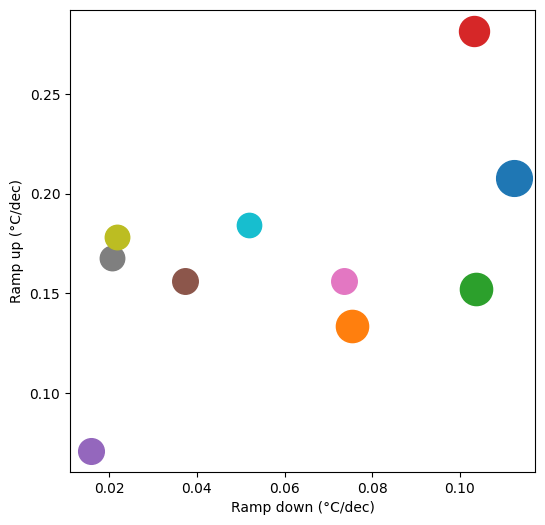

In [136]:
fig = plt.figure(figsize=(6,6))
# ax = fig.add_subplot(projection='3d')

for s,v in tupples.items():
    if v[2] > 0:
        ramp_up = (v[0]-v[1])/v[2]/0.1
        ramp_down = (v[0]-v[1])/v[3]/0.1
        plt.scatter(ramp_down,ramp_up, s = v[0]*200)#s=v[2]*300+50)
plt.xlabel('Ramp down (°C/dec)')
plt.ylabel('Ramp up (°C/dec)')
# plt.legend(fontsize=8)

# Using full PROVIDE ensemble of temps

In [27]:
from util.overshoots import OS_model
from scipy.optimize import curve_fit

In [13]:
folder = '../../Data/PROVIDE 2025/fair_temperatures/'
scenarios = os.listdir(folder)
scenarios = [s[5:] for s in scenarios]
print(scenarios)

['CurPol nz 2120 decline -23800.csv', 'CurPol.csv', 'GS.csv', 'GS_NZGHG.csv', 'LD.csv', 'LD_NZGHG.csv', 'ModAct nz 2120 decline -16500.csv', 'ModAct nz 2120 decline -23000.csv', 'ModAct.csv', 'Neg nz 2100 decline -17000.csv', 'Neg.csv', 'Neg_NZGHG.csv', 'Ref_1p5.csv', 'Ren.csv', 'Ren_NZCO2.csv', 'SP.csv', 'SP_NZGHG.csv', 'ssp119.csv', 'ssp534-over.csv']


In [21]:
df_scen = pd.read_csv(folder+'scen_'+'ssp534-over.csv')
df_scen=df_scen.set_index('year')
years=df_scen.index.values
temps = df_scen.to_numpy()

In [32]:
temps.mean(axis=1)[t_ref-1850]

np.float64(1.1439157800625799)

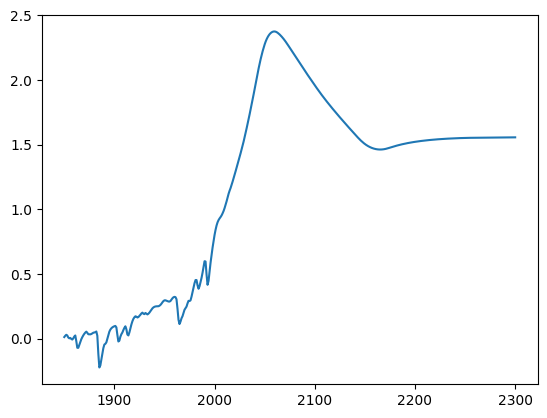

In [40]:
plt.plot(years,temps.mean(axis=1))

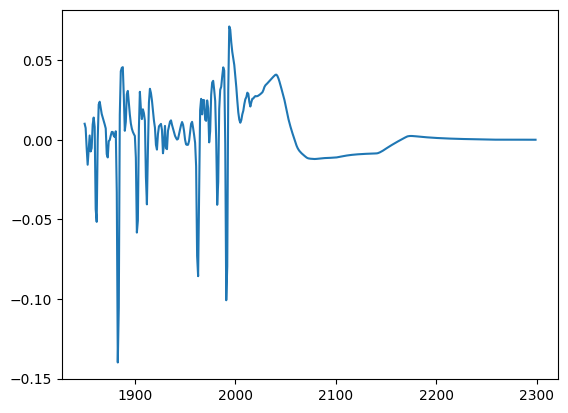

In [43]:
plt.plot(years[:-1],np.diff(temps.mean(axis=1)))

In [71]:
t_ref = 2015

xdata = years[t_ref-1850:]-t_ref
ydata=temps[t_ref-1850:,:].mean(axis=1)
T_ref = ydata[0]
T_max = ydata.max()
yr_peak = years[np.argmax(temps.mean(axis=1))]

popt, pcov = curve_fit(OS_model, xdata, ydata,
                       p0=[T_ref, T_max, temps.mean(axis=1)[-1], yr_peak-2015, 10 , (years[-1]-yr_peak)/2],
                       bounds = ([T_ref-0.5, T_max-0.5, temps[-1,:].min(), 10, 0, 10],
                                 [T_ref+0.5, T_max+0.5, temps[-1,:].max(), len(xdata), 100, len(xdata)]) )

(2000.0, 2050.0)

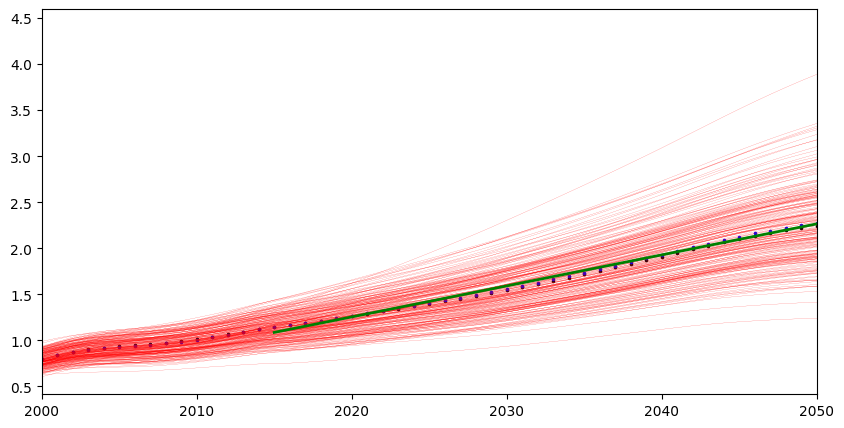

In [175]:
fig=plt.figure(figsize=(10,5))
t_ref=2000
for r in range(0,temps.shape[1],10):
    plt.plot(years[t_ref-1850:],temps[t_ref-1850:,r],lw=0.1,c='r')
plt.scatter(years[t_ref-1850:],np.median(temps,axis=1)[t_ref-1850:],c='k',marker='.',s=10)
plt.scatter(years[t_ref-1850:],np.mean(temps,axis=1)[t_ref-1850:],c='b',marker='.',s=10)
plt.plot(xdata+2015,OS_model(xdata,*popt),label='fit',lw=2,c='g')
plt.xlim(2000,2050)

In [103]:
def OS_fit(xdata,ydata):
    return curve_fit(OS_model, xdata, ydata,
                       p0=[ydata[0], ydata.max(), ydata[-1], 
                           xdata[np.argmax(ydata)], 10 , (xdata[-1]-xdata[np.argmax(ydata)])/2],
                       bounds = ([ydata[0]-0.5, ydata.max()-0.5, ydata[-1]-0.5, 
                                  0, 0, 0],
                                 [ydata[0]+0.5, ydata.max()+0.5, ydata[-1]+0.5, 
                                  len(xdata), 100, len(xdata)]) )

In [104]:
popts = np.array([OS_fit(xdata,temps[t_ref-1850:,r])[0] for r in range(temps.shape[1])])

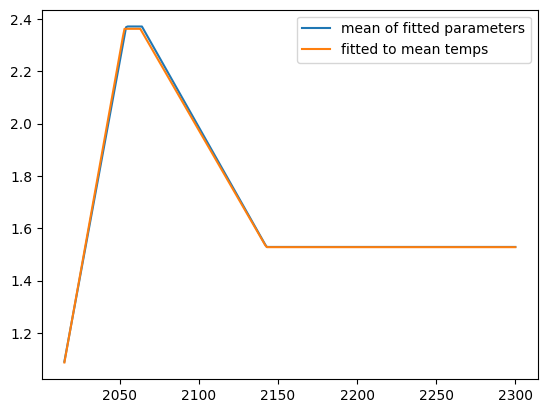

In [113]:
pm = popts.mean(axis=0)
plt.plot(xdata+t_ref,OS_model(xdata,*pm),label='mean of fitted parameters')
plt.plot(xdata+t_ref,OS_model(xdata,*popt),label='fitted to mean temps')
plt.legend()

Text(0, 0.5, 'Duration (y)')

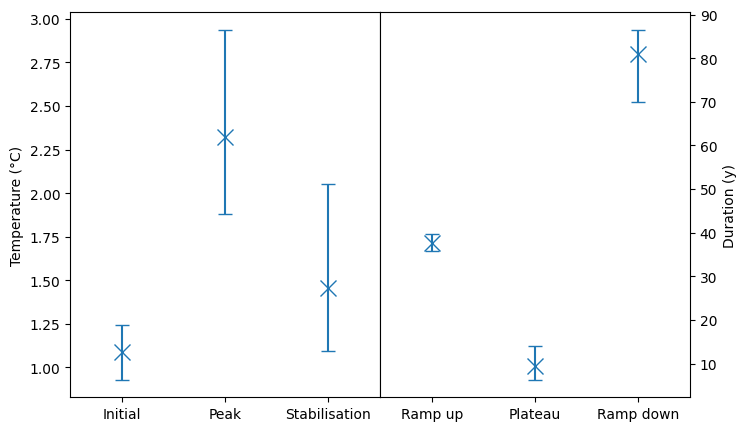

In [153]:
fig,axs=plt.subplots(figsize=(8,5),ncols=2,sharex=False,sharey=False)
fig.subplots_adjust(wspace=0.0)
axs[1].yaxis.set_label_position("right")
axs[1].yaxis.tick_right()

pm=np.median(popts,axis=0)
axs[0].set_xlim(-0.5,2.5)
axs[0].errorbar(np.arange(3),pm[:3],
                yerr=np.abs(np.array([np.quantile(popts[:,:3],q,axis=0) for q in [0.1,0.9]])-pm[:3]),
                capsize=5,ls='',marker='x',ms=12)
axs[0].set_xticks(np.arange(3),labels=['Initial','Peak','Stabilisation'])
axs[0].set_ylabel('Temperature (°C)')

axs[1].set_xlim(-0.5,2.5)
axs[1].errorbar(np.arange(3),pm[3:],
                yerr=np.abs(np.array([np.quantile(popts[:,3:],q,axis=0) for q in [0.1,0.9]])-pm[3:]),
                capsize=5,ls='',marker='x',ms=12)
axs[1].set_xticks(np.arange(3),labels=['Ramp up','Plateau','Ramp down'])
axs[1].set_ylabel('Duration (y)')

(1.0872483271139015, 4.5302849992896865)

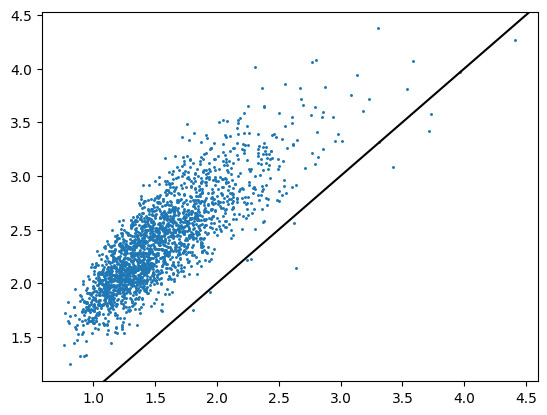

In [166]:
plt.scatter(popts[:,2],popts[:,1],marker='.',s=5)
xlim=plt.gca().get_xlim()
ylim=plt.gca().get_ylim()
plt.plot(xlim,xlim,c='k')
plt.xlim(xlim)
plt.ylim(ylim)

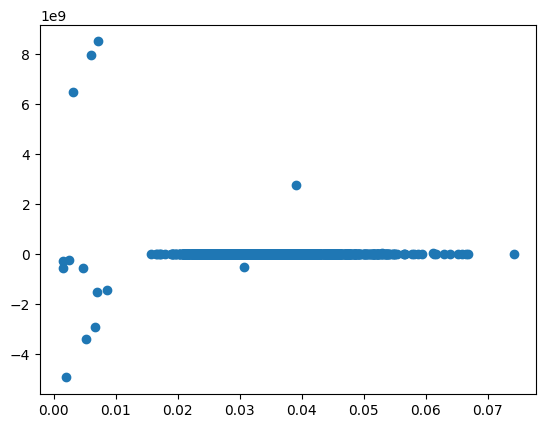

In [155]:
plt.scatter((popts[:,1]-popts[:,0])/popts[:,3], 
            (popts[:,1]-popts[:,2])/popts[:,5])

In [119]:
for k in range(6):
    print([np.quantile(popts[:,k],q) for q in [0.1,0.5,0.9]])

[np.float64(0.928486575996955), np.float64(1.0882882588076497), np.float64(1.2454092882030319)]
[np.float64(1.8777354302058502), np.float64(2.321685708622256), np.float64(2.9372484853297856)]
[np.float64(1.0951867570159324), np.float64(1.4540463087253703), np.float64(2.0514490626999042)]
[np.float64(35.85938626528022), np.float64(37.70438427551494), np.float64(39.79895876543347)]
[np.float64(6.269070112230649), np.float64(9.363605400057702), np.float64(13.930695749826773)]
[np.float64(69.97669411802248), np.float64(80.92441619366546), np.float64(86.50344695694665)]
